In [90]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols, sqrt, log, exp, lambdify, latex
from IPython.display import display, Math

In [91]:
N = 10_000
left, right = 1.0, 10.0

In [92]:
# def f1(x):
#     return x**2


# def f2(x):
#     return np.exp(x)


# def f3(x):
#     return -np.log(x)


# def f4(x):
#     return np.sqrt(1 + x**2)

x = symbols("x")

f1 = x**2
f2 = exp(x)
f3 = -log(x)
f4 = sqrt(1 + x**2)

sympy_function = [f1, f2, f3, f4]

In [93]:
def latex_sci(x):
    if x == 0:
        return "0"

    exponent = int(np.floor(np.log10(abs(x))))
    mantissa = x / 10**exponent

    return f"{mantissa:.3f}\\times10^{{{exponent}}}"

In [104]:
np.random.seed(0)  # For reproducibility

# lambdified_functions = [lambdify(x, f, 'numpy') for f in sympy_function]

for f in sympy_function:
    f_numpy = lambdify(x, f, "numpy")
    max_violation = -np.inf

    for _ in range(N):
        x_grid = np.random.uniform(left, right, N)

        lam = np.random.rand(N)
        lam /= np.sum(lam)

        D = f_numpy(np.sum(lam * x_grid)) - np.sum(lam * f_numpy(x_grid))

        max_violation = max(max_violation, D)

    display(Math(f"\\varepsilon_{{max}}({latex(f)}) = {latex_sci(max_violation)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [95]:
np.random.seed(0)  # For reproducibility
max_violation_ln = -np.inf
for _ in range(10_000):
    x_grid = np.random.uniform(left, right, N)
    expr = np.mean(x_grid) - np.exp(np.mean(np.log(x_grid)))
    max_violation_ln = max(max_violation_ln, expr)
display(Math(f"\\varepsilon_{{max}}(\\log(x)) = {latex_sci(max_violation_ln)}"))

<IPython.core.display.Math object>

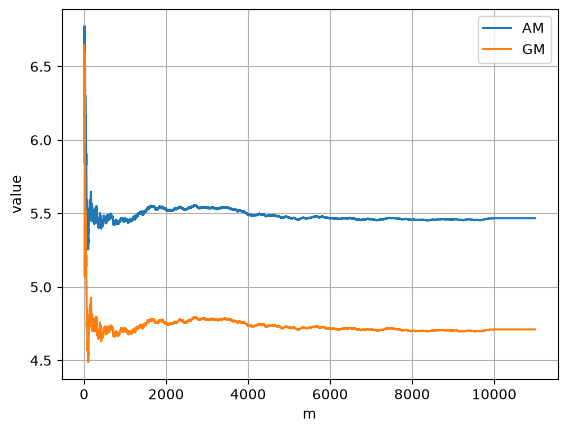

In [96]:
np.random.seed(0)

x_all = np.random.uniform(left, right, N)
m_values = np.arange(2, 11000)

AM_values = []
GM_values = []

for m in m_values:
    x_m = x_all[:m]

    AM = np.mean(x_m)
    GM = np.exp(np.mean(np.log(x_m)))

    AM_values.append(AM)
    GM_values.append(GM)

plt.plot(m_values, AM_values, label="AM")
plt.plot(m_values, GM_values, label="GM")

plt.xlabel("m")
plt.ylabel("value")

plt.legend()
plt.grid()
plt.show()

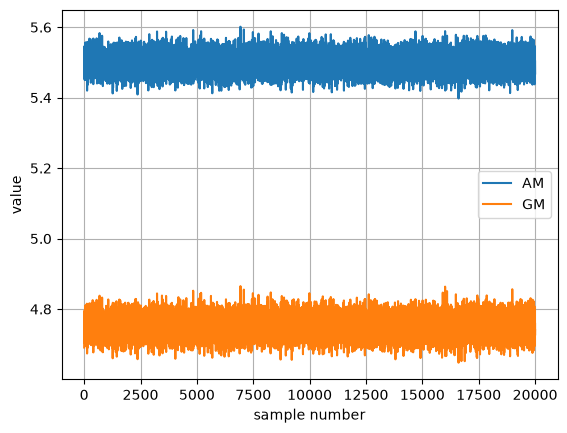

In [97]:
m = N

AM_values = []
GM_values = []

for _ in range(2 * N):
    x_m = np.random.uniform(left, right, m)

    AM = np.mean(x_m)
    GM = np.exp(np.mean(np.log(x_m)))

    AM_values.append(AM)
    GM_values.append(GM)

plt.plot(AM_values, label="AM")
plt.plot(GM_values, label="GM")

plt.xlabel("sample number")
plt.ylabel("value")

plt.legend()
plt.grid()
plt.show()

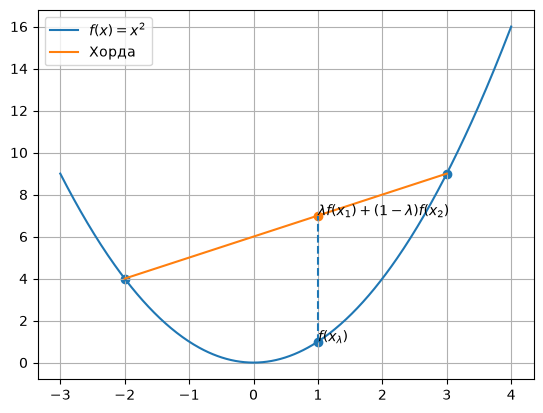

1.0
1.0
7.0


In [98]:
def f(x):
    return x**2


x1 = -2
x2 = 3

lam = 0.4

y1 = f(x1)
y2 = f(x2)

x_lam = lam * x1 + (1 - lam) * x2
y_lam = f(x_lam)
y_chord = lam * y1 + (1 - lam) * y2


x_grid = np.linspace(-3, 4, 400)

plt.plot(x_grid, f(x_grid), label="$f(x)=x^2$")
plt.plot([x1, x2], [y1, y2], label="Хорда")
plt.scatter([x1, x2, x_lam], [y1, y2, y_lam])
plt.vlines(x_lam, y_lam, y_chord, linestyle="--")
plt.scatter(x_lam, y_chord)

plt.text(x_lam, y_lam, "$f(x_\\lambda)$")
plt.text(x_lam, y_chord, "$\\lambda f(x_1)+(1-\\lambda)f(x_2)$")

plt.grid()
plt.legend()
plt.show()

print(round(x_lam, 3))
print(round(y_lam, 3))
print(round(y_chord, 3))